# 02 · E91 with CHSH Security: IBM Quantum Hardware

Part of the project *Entanglement-Based QKD with Bell-Test Security on IBM Quantum Hardware*.

This notebook runs the E91 protocol from notebook 01 on the IBM Fez processor and compares the results with a noise model of the same device:

1. A dry run on a simulated copy of IBM Fez using its calibrated noise model.
2. The same circuits on real hardware through Qiskit Runtime.
3. Analysis of the CHSH value $S$ with its statistical uncertainty, the QBER, and the device-independent and BBM92 key rates (Figures 5 and 6).

Raw hardware outcomes are stored in `hardware_results.json`, so the analysis can be reproduced without rerunning on hardware.

## Setup

In [1]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [2]:
import json, getpass, datetime
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.fake_provider import FakeTorino

try:
    # client-side Sampler, qiskit-ibm-runtime >= 0.50
    from qiskit_ibm_runtime.executor_sampler import Sampler
except ImportError:
    from qiskit_ibm_runtime import SamplerV2 as Sampler

print("Qiskit version:", qiskit.__version__)
print("qiskit-ibm-runtime version:", qiskit_ibm_runtime.__version__)

Qiskit version: 2.6.2
qiskit-ibm-runtime version: 0.52.1


In [12]:
from qiskit_ibm_runtime.fake_provider import FakeFez
fake_backend = AerSimulator.from_backend(FakeFez())

## 1. Circuits and analysis

The measurement settings match notebook 01: Alice uses $a_0 = 0$ and $a_1 = \pi/2$; Bob uses $b_0 = \pi/4$, $b_1 = -\pi/4$ and $b_2 = 0$. The five setting pairs that contribute to the protocol (one key pair and four CHSH pairs) are each run as a separate circuit with 4,000 shots. For independent, identically distributed rounds this gives the same statistics as choosing settings at random in each round, although a deployed protocol would need random settings that stay secret until after measurement.

Each correlator has statistical uncertainty $\sigma_E = \sqrt{(1 - E^2)/N}$, so

$$\sigma_S = \sqrt{\sum_{(i,j)} \frac{1 - E_{ij}^2}{N}}.$$

Readout-error mitigation is deliberately not applied: it relies on a model of the measurement devices, which a device-independent analysis does not trust.

In [3]:
A_ANGLES = [0.0, np.pi / 2]
B_ANGLES = [np.pi / 4, -np.pi / 4, 0.0]
KEY_PAIR = (0, 2)
CHSH_PAIRS = [(0, 0), (0, 1), (1, 0), (1, 1)]
CHSH_SIGNS = {(0, 0): 1, (0, 1): 1, (1, 0): 1, (1, 1): -1}
PUB_PAIRS = [KEY_PAIR] + CHSH_PAIRS
SHOTS = 4000


def e91_circuit(i, j):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()
    qc.ry(-A_ANGLES[i], 0)
    qc.ry(-B_ANGLES[j], 1)
    qc.measure([0, 1], [0, 1])
    qc.name = f"a{i}_b{j}"
    return qc


circuits = [e91_circuit(i, j) for (i, j) in PUB_PAIRS]
print(circuits[1].draw())

     ┌───┐      ░  ┌───────┐  ┌─┐   
q_0: ┤ H ├──■───░──┤ Ry(0) ├──┤M├───
     └───┘┌─┴─┐ ░ ┌┴───────┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─░─┤ Ry(-π/4) ├─╫─┤M├
          └───┘ ░ └──────────┘ ║ └╥┘
c: 2/══════════════════════════╩══╩═
                               0  1 


In [4]:
def h(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return float(-x * np.log2(x) - (1 - x) * np.log2(1 - x))


def rate_di(S, Q):
    if S <= 2:
        return 0.0
    S = min(S, 2 * np.sqrt(2))
    return max(0.0, 1 - h(Q) - h((1 + np.sqrt((S / 2) ** 2 - 1)) / 2))


def rate_bbm92(Q):
    return max(0.0, 1 - 2 * h(Q))


def analyze(bitstrings):
    # bitstrings: dict "a{i}_b{j}" -> list of outcome strings 'ba' (Bob, Alice)
    def split(mem):
        a = np.array([int(s[-1]) for s in mem])
        b = np.array([int(s[-2]) for s in mem])
        return a, b

    E, var_S = {}, 0.0
    for (i, j) in CHSH_PAIRS:
        a, b = split(bitstrings[f"a{i}_b{j}"])
        E[(i, j)] = float(np.mean((1 - 2 * a) * (1 - 2 * b)))
        var_S += (1 - E[(i, j)] ** 2) / len(a)
    S = sum(CHSH_SIGNS[p] * E[p] for p in CHSH_PAIRS)

    ka, kb = split(bitstrings[f"a{KEY_PAIR[0]}_b{KEY_PAIR[1]}"])
    Q = float(np.mean(ka != kb))
    return {"E": E, "S": S, "sigma_S": float(np.sqrt(var_S)), "qber": Q,
            "sigma_Q": float(np.sqrt(Q * (1 - Q) / len(ka))), "n_key": len(ka),
            "r_di": rate_di(S, Q), "r_bbm92": rate_bbm92(Q), "key_a": ka, "key_b": kb}


def report(res, label):
    print(label)
    for p in CHSH_PAIRS:
        print(f"  E(a{p[0]}, b{p[1]}) = {res['E'][p]:+.3f}")
    sig = (res["S"] - 2) / res["sigma_S"]
    print(f"  S = {res['S']:.3f} ± {res['sigma_S']:.3f}   ({sig:.1f} standard deviations above 2)")
    print(f"  QBER = {res['qber']:.4f} ± {res['sigma_Q']:.4f}   (key bits: {res['n_key']})")
    print(f"  r_DI = {res['r_di']:.3f}   r_BBM92 = {res['r_bbm92']:.3f}")

## 2. Dry run on a simulated IBM device

`FakeFez` reproduces the qubit layout, gate set and a calibrated noise snapshot of IBM Fez, the processor used for the hardware run. Running the circuits on this model first validates the pipeline and gives a prediction to compare against the hardware.

In [13]:
pm_fake = generate_preset_pass_manager(backend=fake_backend, optimization_level=1)
isa_fake = pm_fake.run(circuits)

job = fake_backend.run(isa_fake, shots=SHOTS, memory=True, seed_simulator=7)
fake_bits = {qc.name: job.result().get_memory(k) for k, qc in enumerate(circuits)}

res_fake = analyze(fake_bits)
report(res_fake, "Simulated IBM Torino (noise model)")

Simulated IBM Torino (noise model)
  E(a0, b0) = +0.663
  E(a0, b1) = +0.652
  E(a1, b0) = +0.673
  E(a1, b1) = -0.695
  S = 2.683 ± 0.023   (29.2 standard deviations above 2)
  QBER = 0.0328 ± 0.0028   (key bits: 4000)
  r_DI = 0.494   r_BBM92 = 0.584


## 3. Real hardware

The circuits were run on `ibm_fez`, selected as the least busy available device, using the IBM Quantum Open Plan. The API key is entered through a hidden prompt and is not stored in the notebook. The five circuits of 4,000 shots each used a few seconds of quantum time.

In [6]:
token = getpass.getpass("IBM Quantum API key: ")
instance = input("Instance CRN or name (press Enter to skip): ").strip() or None
service = QiskitRuntimeService(token=token, instance=instance) if instance else QiskitRuntimeService(token=token)
del token

backend = service.least_busy(operational=True, simulator=False)
print("Selected backend:", backend.name, f"({backend.num_qubits} qubits)")

IBM Quantum API key: ··········
Instance CRN or name (press Enter to skip): 


qiskit_runtime_service._discover_account:WARNING:2026-11-26 09:41:41,971: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-26 09:41:45,777: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-26 09:41:46,449: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-26 09:41:49,189: Using instance: open-instance, plan: open


Selected backend: ibm_fez (156 qubits)


In [7]:
pm_hw = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_hw = pm_hw.run(circuits)
print("Physical qubits used:", isa_hw[0].layout.final_index_layout()[:2])

sampler = Sampler(mode=backend)
hw_job = sampler.run(isa_hw, shots=SHOTS)
print("Job ID:", hw_job.job_id(), "  (save this to retrieve the result later)")

qiskit_runtime_service.backends:WARNING:2026-11-26 09:42:42,660: Using instance: open-instance, plan: open


Physical qubits used: [0, 1]
Job ID: dc3vu4thdvas73boma8g   (save this to retrieve the result later)


In [9]:
hw_result = hw_job.result()      # waits until the job has finished
hw_bits = {qc.name: hw_result[k].data.c.get_bitstrings() for k, qc in enumerate(circuits)}

record = {
    "backend": backend.name,
    "job_id": hw_job.job_id(),
    "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "shots_per_circuit": SHOTS,
    "settings": {"alice": A_ANGLES, "bob": B_ANGLES},
    "bitstrings": hw_bits,
}
with open("hardware_results.json", "w") as f:
    json.dump(record, f)
print("Saved hardware_results.json")

res_hw = analyze(hw_bits)
report(res_hw, f"IBM hardware: {backend.name}")

Saved hardware_results.json
IBM hardware: ibm_fez
  E(a0, b0) = +0.643
  E(a0, b1) = +0.640
  E(a1, b0) = +0.628
  E(a1, b1) = -0.659
  S = 2.571 ± 0.024   (23.6 standard deviations above 2)
  QBER = 0.0473 ± 0.0034   (key bits: 4000)
  r_DI = 0.269   r_BBM92 = 0.451


The saved results can be reanalysed with `analyze(json.load(open("hardware_results.json"))["bitstrings"])`.

## 4. Comparison

Figure 5 compares the ideal protocol, the `FakeFez` noise model and the hardware run. Figure 6 places the measured key rates on the white-noise curves from notebook 01.

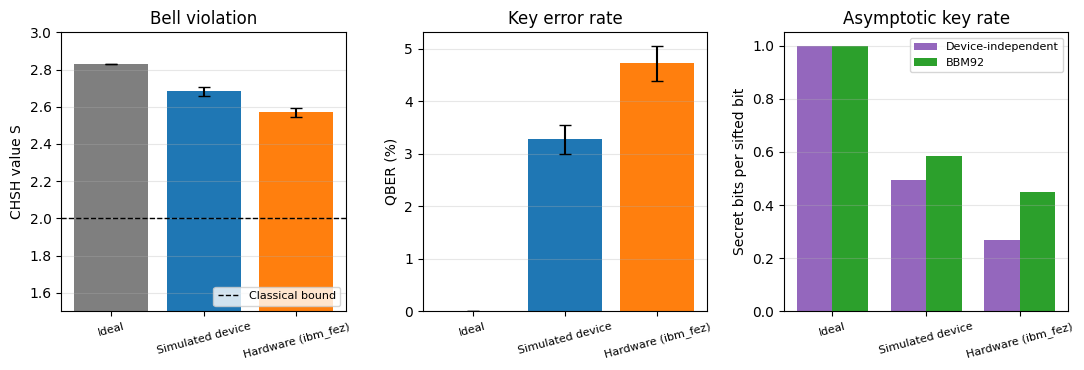

In [14]:
ideal = {"S": 2 * np.sqrt(2), "sigma_S": 0.0, "qber": 0.0, "sigma_Q": 0.0,
         "r_di": 1.0, "r_bbm92": 1.0}
runs = [("Ideal", ideal, "tab:gray"),
        ("Simulated device", res_fake, "tab:blue"),
        (f"Hardware ({record['backend']})", res_hw, "tab:orange")]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
names = [r[0] for r in runs]
x = np.arange(len(runs))

ax = axes[0]
ax.bar(x, [r[1]["S"] for r in runs], yerr=[r[1]["sigma_S"] for r in runs],
       color=[r[2] for r in runs], capsize=4)
ax.axhline(2, color="black", linestyle="--", linewidth=1, label="Classical bound")
ax.set_ylim(1.5, 3.0)
ax.set_ylabel("CHSH value S")
ax.set_title("Bell violation")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
ax.bar(x, [100 * r[1]["qber"] for r in runs], yerr=[100 * r[1]["sigma_Q"] for r in runs],
       color=[r[2] for r in runs], capsize=4)
ax.set_ylabel("QBER (%)")
ax.set_title("Key error rate")

ax = axes[2]
w = 0.38
ax.bar(x - w / 2, [r[1]["r_di"] for r in runs], w, color="tab:purple", label="Device-independent")
ax.bar(x + w / 2, [r[1]["r_bbm92"] for r in runs], w, color="tab:green", label="BBM92")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Secret bits per sifted bit")
ax.set_title("Asymptotic key rate")
ax.legend(fontsize=8)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=15, fontsize=8)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.savefig("fig5_hardware_summary.png", dpi=200)
plt.show()

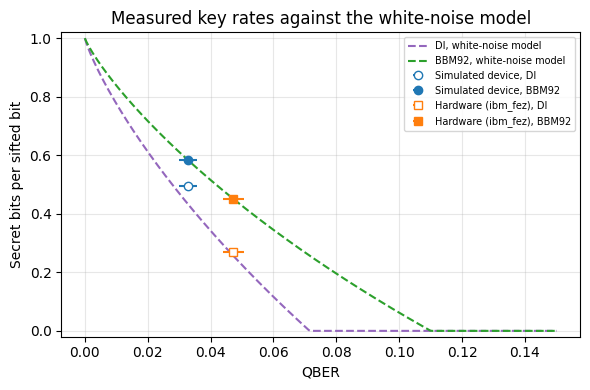

In [15]:
# where the simulated device and the hardware sit on the white-noise key-rate curves
p_fine = np.linspace(0, 0.3, 300)
Q_curve = p_fine / 2
rdi_curve = [rate_di(2 * np.sqrt(2) * (1 - p), p / 2) for p in p_fine]
rbb_curve = [rate_bbm92(p / 2) for p in p_fine]

plt.figure(figsize=(6, 4))
plt.plot(Q_curve, rdi_curve, "--", color="tab:purple", label="DI, white-noise model")
plt.plot(Q_curve, rbb_curve, "--", color="tab:green", label="BBM92, white-noise model")
for label, r, c, m in [("Simulated device", res_fake, "tab:blue", "o"),
                       (f"Hardware ({record['backend']})", res_hw, "tab:orange", "s")]:
    plt.errorbar(r["qber"], r["r_di"], xerr=r["sigma_Q"], fmt=m, color=c, mfc="white",
                 label=f"{label}, DI")
    plt.errorbar(r["qber"], r["r_bbm92"], xerr=r["sigma_Q"], fmt=m, color=c,
                 label=f"{label}, BBM92")
plt.xlabel("QBER")
plt.ylabel("Secret bits per sifted bit")
plt.title("Measured key rates against the white-noise model")
plt.ylim(-0.02, 1.02)
plt.legend(fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig6_hardware_on_rate_curve.png", dpi=200)
plt.show()

## 5. Discussion

- **Bell violation on hardware.** On `ibm_fez`, $S = 2.571 \pm 0.024$, which is 23.6 standard deviations above the classical bound of 2. The four correlators are nearly equal in magnitude ($|E| \approx 0.64$, ideal $0.707$).
- **Positive device-independent key rate.** With QBER $= 4.7 \pm 0.3\%$, the asymptotic rates are $r_{\text{DI}} = 0.27$ and $r_{\text{BBM92}} = 0.45$ secret bits per sifted bit. The DI rate is lower because it does not trust the devices.
- **Consistent with white noise.** Under a white-noise model, $S = 2.571$ corresponds to visibility $v = S/2\sqrt{2} = 0.909$, which predicts a QBER of $(1-v)/2 = 4.5\%$. The measured $4.7 \pm 0.3\%$ agrees within one standard deviation, so on this device the Bell violation and key error rate degrade together, as expected for approximately depolarizing noise.
- **Hardware vs. noise model.** The `FakeFez` model gives $S = 2.683 \pm 0.023$ and QBER $= 3.3 \pm 0.3\%$. The real device is noisier by about 3.4 standard deviations in both quantities, reflecting calibration drift since the snapshot, a possibly different choice of physical qubits, and noise the model omits, such as crosstalk and leakage. A model of an older processor (`FakeTorino`) did not reproduce a Bell violation at all ($S = 1.80$), so a device-specific model is needed for meaningful predictions.

**Caveats.** Both qubits sit on one processor, so locality and detection loopholes are open and the devices are not truly independent. Measurement settings were assigned in fixed blocks rather than chosen randomly per round. The key rates are asymptotic and ignore finite-size effects. The result demonstrates the protocol and its Bell-test-based security analysis on real quantum hardware, not a deployed QKD link.